<a href="https://colab.research.google.com/github/leman973/Deep-Learning/blob/main/Pract_3_CNN_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Input, Dropout

In [4]:
(x_train,y_train),(x_test,y_test) = keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
x_train = x_train/255.0
x_test = x_test/255.0

In [6]:
print("X_train shape: ",x_train.shape)
print("X_test shape: ", x_test.shape)

X_train shape:  (60000, 28, 28)
X_test shape:  (10000, 28, 28)


In [7]:
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

In [8]:
print("X_train shape: ",x_train.shape)
print("X_test shape: ", x_test.shape)

X_train shape:  (60000, 28, 28, 1)
X_test shape:  (10000, 28, 28, 1)


In [14]:
model = Sequential([
    Input(shape=(28,28,1)),
    Conv2D(32,(3,3),activation = "relu"),
    MaxPooling2D(2,2),
    Dropout(0.3),

    Conv2D(64,(3,3),activation = "relu"),
    MaxPooling2D(2,2),
    Dropout(0.3),

    Flatten(),
    Dense(128,activation = "relu"),
    Dropout(0.3),
    Dense(10,activation = "softmax")
])

In [15]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history = model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [17]:
model.fit(x_train,y_train,epochs = 20, batch_size = 64,validation_split = 0.1)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 60s 69ms/step - accuracy: 0.7756 - loss: 0.6137 - val_accuracy: 0.8515 - val_loss: 0.3980
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 58s 69ms/step - accuracy: 0.8488 - loss: 0.4126 - val_accuracy: 0.8728 - val_loss: 0.3404
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 69ms/step - accuracy: 0.8652 - loss: 0.3674 - val_accuracy: 0.8888 - val_loss: 0.3035
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 56s 66ms/step - accuracy: 0.8759 - loss: 0.3398 - val_accuracy: 0.8837 - val_loss: 0.3053
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 67ms/step - accuracy: 0.8824 - loss: 0.3180 - val_accuracy: 0.8928 - val_loss: 0.2870
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 56s 67ms/step - accuracy: 0.8867 - loss: 0.3030 - val_accuracy: 0.8988 - val_loss: 0.2791
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 56s 67ms/step - accuracy: 0.8920 - loss: 0.2911 - val_accuracy: 0.9045 - val_loss: 0.2589
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 57s 68ms/step - accuracy: 0.8951 - loss: 0.2821 - 

In [18]:
test_loss, test_accuracy = model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9104 - loss: 0.2419


In [22]:
predict = model.predict(x_test)
predictions = np.argmax(predict, axis = 1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


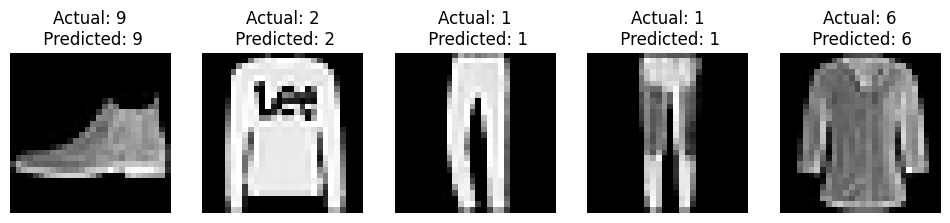

In [23]:
plt.figure(figsize=(12,5))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(x_test[i].reshape(28,28),cmap = "gray")
  plt.title(f"Actual: {y_test[i]}\n Predicted: {predictions[i]}")
  plt.axis("off")
plt.show()